In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Una empresa promueve un parque eólico de **8 aerogeneradores de 5.0 MW (40 MW)**. El cuadro de prelaciones, las duraciones medias (meses) y las desviaciones típicas se adjuntan; la actividad **A** es la tramitación ambiental, con la duración estimada del procedimiento **simplificado** (4 meses). Si el proyecto requiere evaluación **ordinaria**, la experiencia de la empresa es que A dura 4 meses más.

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, standard_deviation
    ('A'     , '---'      , 4       , 1                 ),
    ('B'     , '---'      , 1       , 0.1               ),
    ('C'     , 'A,B'      , 2       , 0.8               ),
    ('D'     , 'C'        , 7       , 0.3               ),
    ('E'     , 'A'        , 1       , 0.6               ),
    ('F'     , 'D'        , 1       , 1                 ),
    ('G'     , 'C'        , 5       , 0.3               ),
    ('H'     , 'F'        , 5       , 1                 ),
    ('I'     , 'E,G'      , 6       , 0.8               ),
], columns=['activity', 'predecessor', 'duration', 'standard_deviation']).set_index('activity')
datos_enunciado

,predecessor,duration,standard_deviation
activity,,,
A,---,4,1.0
B,---,1,0.1
C,"A,B",2,0.8
D,C,7,0.3
E,A,1,0.6
F,D,1,1.0
G,C,5,0.3
H,F,5,1.0
I,"E,G",6,0.8


Los permisos de acceso y conexión a la red caducan si la autorización de construcción no se obtiene antes del **mes 22** (hito administrativo); perderlos supone volver a la cola de acceso.

> **De: Director de desarrollo**
> Lo presentamos como dos parques «independientes» de 4 y 4 aerogeneradores (20 y 20 MW), contiguos, promovidos por dos sociedades del grupo: cada uno queda por debajo del umbral del anexo I, va por el procedimiento simplificado y llegamos al hito. Si alguien pregunta, son dos proyectos distintos.

## Criterio de referencia

Las preguntas del bloque **B** se responden aplicando los criterios siguientes, tomados de la lección 20 (redactados por el curso; cada uno remite a la fuente de la que procede, que no se reproduce). La respuesta se justifica citando el criterio y la fuente, no con una opinión.

- **S9 — Evaluación ambiental del conjunto.** El procedimiento de evaluación ambiental que corresponde a un proyecto se determina por sus magnitudes totales: los proyectos que, presentándose fraccionados, alcanzan por acumulación los umbrales del anexo I se evalúan como uno solo, con el procedimiento ordinario. Fraccionar para quedar bajo el umbral no cambia el procedimiento exigible; cambia el riesgo de nulidad y el plazo (cf. C7 de la lección 19). *(cf. Ley 21/2013 de evaluación ambiental, arts. 7.1.a) y 7.2.d) y anexos I y II.)*
- **S11 — Riesgo de sostenibilidad.** Una amenaza ambiental, climática, regulatoria o social que puede cambiar el plazo, el coste o el resultado del proyecto es un riesgo del proyecto: entra en el registro con su probabilidad y su impacto y se cuantifica en el cronograma como cualquier otro. Dejarlo fuera «porque es el clima» o «porque es de la administración» es retener información (C4 de la lección 19). *(cf. PMBOK 8 §3.7.1 (riesgos de sostenibilidad) y §3.7.3 (dominio de desempeño del riesgo).)*
- **Norma o dato de referencia — evaluación de impacto ambiental ordinaria (anexo I) para parques eólicos con 50 o más aerogeneradores, más de 30 MW o a menos de 2 km de otro parque, y para plantas solares en suelo de más de 100 ha; simplificada (anexo II) para los parques eólicos no incluidos en el anexo I y las plantas solares en suelo de 5 ha o más. Los proyectos que, presentándose fraccionados, alcanzan por acumulación los umbrales de un anexo se evalúan por ese anexo** *(Ley 21/2013, art. 7.1.a) y 7.2.d), anexos I (grupo 3) y II (grupo 4), redacción del RD 445/2023.)*

Responda a las preguntas: A (cálculo), B (criterio) y C (deliberación).

In [5]:
pregunta_1 = "1. (A) Calcule la duración del proyecto con el procedimiento simplificado y con el ordinario, y el margen (o el retraso) respecto al hito del mes 22 en cada caso.  "
pregunta_2 = "2. (A) Calcule la probabilidad de cumplir el hito en cada caso con la aproximación normal del PERT y con una simulación Monte Carlo (20 000 réplicas, duraciones normales). ¿Qué actividades tendrían que acortarse, y cuánto, para recuperar el margen con el procedimiento ordinario?  "
pregunta_3 = "3. (B) Según la norma y el criterio de referencia, ¿qué procedimiento corresponde al proyecto? ¿Cambia algo presentarlo en dos partes? ¿Es la tramitación ambiental un riesgo del proyecto o «cosa de la administración»?  "
pregunta_4 = "4. (C) ¿Qué propone al director de desarrollo? Aplique la rúbrica de la lección.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. (A) Calcule la duración del proyecto con el procedimiento simplificado y con el ordinario, y el margen (o el retraso) respecto al hito del mes 22 en cada caso.  

2. (A) Calcule la probabilidad de cumplir el hito en cada caso con la aproximación normal del PERT y con una simulación Monte Carlo (20 000 réplicas, duraciones normales). ¿Qué actividades tendrían que acortarse, y cuánto, para recuperar el margen con el procedimiento ordinario?  

3. (B) Según la norma y el criterio de referencia, ¿qué procedimiento corresponde al proyecto? ¿Cambia algo presentarlo en dos partes? ¿Es la tramitación ambiental un riesgo del proyecto o «cosa de la administración»?  

4. (C) ¿Qué propone al director de desarrollo? Aplique la rúbrica de la lección.  

# Resolución

In [6]:
tramitacion, meses_mas, hito = 'A', 4, 22
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion = int(proyecto.duration(datos_proyecto['duration']))
datos_proyecto['variance'] = datos_proyecto['standard_deviation'] ** 2
duraciones_ordinaria = datos_proyecto['duration'].copy(); duraciones_ordinaria[tramitacion] += meses_mas
duracion_ordinaria = int(proyecto.duration(duraciones_ordinaria))

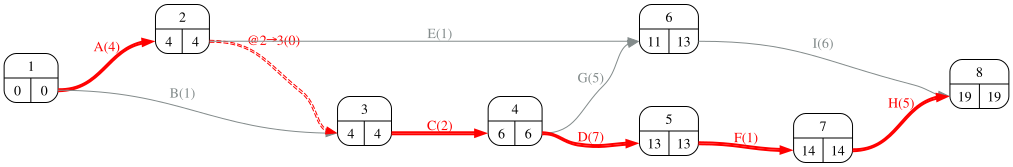

In [8]:
#| fig-cap: "Grafo PERT con el procedimiento simplificado"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

Cálculo de los tiempos tempranos y tardíos de los sucesos paso a paso (avance con los botones):

In [7]:
proyecto.display_pert_pasos(datos_proyecto['duration'])

**Tiempos tempranos (hacia delante)**

- $t_{1} = 0$
- $t_{2} = 0+4 = 4$ &nbsp; (A)
- $t_{3} = \max\{4+0,\ 0+1\} = 4$ &nbsp; (@2→3, B)
- $t_{4} = 4+2 = 6$ &nbsp; (C)
- $t_{5} = 6+7 = 13$ &nbsp; (D)
- $t_{6} = \max\{4+1,\ 6+5\} = 11$ &nbsp; (E, G)
- $t_{7} = 13+1 = 14$ &nbsp; (F)
- $t_{8} = \max\{14+5,\ 11+6\} = 19$ &nbsp; (H, I)

**Tiempos tardíos (hacia atrás)**

- $t_{8}^{*} = t_{8} = 19$
- $t_{7}^{*} = 19-5 = 14$ &nbsp; (H)
- $t_{6}^{*} = 19-6 = 13$ &nbsp; (I)
- $t_{5}^{*} = 14-1 = 13$ &nbsp; (F)
- $t_{4}^{*} = \min\{13-7,\ 13-5\} = 6$ &nbsp; (D, G)
- $t_{3}^{*} = 6-2 = 4$ &nbsp; (C)
- $t_{2}^{*} = \min\{4-0,\ 13-1\} = 4$ &nbsp; (@2→3, E)
- $t_{1}^{*} = \min\{4-4,\ 4-1\} = 0$ &nbsp; (A, B)

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. (A) Calcule la duración del proyecto con el procedimiento simplificado y con el ordinario, y el margen (o el retraso) respecto al hito del mes 22 en cada caso.  

In [10]:
Markdown(f'''Procedimiento simplificado: **{duracion}** meses, margen de {hito - duracion} sobre el hito. Procedimiento ordinario: **{duracion_ordinaria}** meses, ''' + (f'retraso de {duracion_ordinaria - hito}' if duracion_ordinaria > hito else f'margen de {hito - duracion_ordinaria}') + f''' respecto al hito (la tramitación es crítica: los {meses_mas} meses van enteros al plazo).''')

Procedimiento simplificado: **19** meses, margen de 3 sobre el hito. Procedimiento ordinario: **23** meses, retraso de 1 respecto al hito (la tramitación es crítica: los 4 meses van enteros al plazo).

## Apartado 2

In [11]:
display(Markdown(pregunta_2))

2. (A) Calcule la probabilidad de cumplir el hito en cada caso con la aproximación normal del PERT y con una simulación Monte Carlo (20 000 réplicas, duraciones normales). ¿Qué actividades tendrían que acortarse, y cuánto, para recuperar el margen con el procedimiento ordinario?  

In [12]:
#| tbl-cap: "Duración y varianza de cada ruta con el procedimiento ordinario"
#| label: tbl-rutas
R = proyecto.path_matrix(dummies=False)
display(detalle_rutas(R, duraciones_ordinaria, 'duración'))
detalle_rutas(R, datos_proyecto['variance'], 'varianza', 3)

,actividades,duración = suma,duración
Route_1,A - C - D - F - H,A(8) + C(2) + D(7) + F(1) + H(5) = 23,23.0
Route_2,A - C - G - I,A(8) + C(2) + G(5) + I(6) = 21,21.0
Route_3,A - E - I,A(8) + E(1) + I(6) = 15,15.0
Route_4,B - C - D - F - H,B(1) + C(2) + D(7) + F(1) + H(5) = 16,16.0
Route_5,B - C - G - I,B(1) + C(2) + G(5) + I(6) = 14,14.0


,actividades,varianza = suma,varianza
Route_1,A - C - D - F - H,A(1.000) + C(0.640) + D(0.090) + F(1.000) + H(...,3.73
Route_2,A - C - G - I,A(1.000) + C(0.640) + G(0.090) + I(0.640) = 2.370,2.37
Route_3,A - E - I,A(1.000) + E(0.360) + I(0.640) = 2.000,2.0
Route_4,B - C - D - F - H,B(0.010) + C(0.640) + D(0.090) + F(1.000) + H(...,2.74
Route_5,B - C - G - I,B(0.010) + C(0.640) + G(0.090) + I(0.640) = 1.380,1.38


In [13]:
sigma_s, _ = proyecto.standard_deviation(durations=datos_proyecto['duration'], variances=datos_proyecto['variance'])
sigma_o, _ = proyecto.standard_deviation(durations=duraciones_ordinaria, variances=datos_proyecto['variance'])
p_pert_s = float(norm.cdf((hito - duracion) / sigma_s)); p_pert_o = float(norm.cdf((hito - duracion_ordinaria) / sigma_o))
dists_s = {act: ('normal', fila['duration'], fila['standard_deviation']) for act, fila in datos_proyecto.iterrows()}
dists_o = dict(dists_s); dists_o[tramitacion] = ('normal', float(duraciones_ordinaria[tramitacion]), float(datos_proyecto.loc[tramitacion, 'standard_deviation']))
mc_s = proyecto.monte_carlo(dists_s, n_samples=20000, seed=2030)
mc_o = proyecto.monte_carlo(dists_o, n_samples=20000, seed=2030)
p_mc_s = float((np.asarray(mc_s.tau_samples) <= hito).mean()); p_mc_o = float((np.asarray(mc_o.tau_samples) <= hito).mean())
tabla = pd.DataFrame({'simplificado': [duracion, sigma_s, p_pert_s, p_mc_s], 'ordinario': [duracion_ordinaria, sigma_o, p_pert_o, p_mc_o]},
                     index=['duración esperada', 'σ del camino crítico', 'P(T ≤ hito) PERT', 'P(T ≤ hito) Monte Carlo'])
display(tabla.round(2))
Markdown(f'''La probabilidad de llegar al hito pasa de **{p_mc_s:.2f}** a **{p_mc_o:.2f}** con el procedimiento ordinario. Para llegar al hito habría que acortar {max(0, duracion_ordinaria - hito)} meses en actividades críticas distintas de la tramitación (ingeniería y compras en paralelo con la tramitación, lección 10) —y más para recuperar un margen—, o negociar el hito.''')

,simplificado,ordinario
duración esperada,19.00,23.00
σ del camino crítico,1.93,1.93
P(T ≤ hito) PERT,0.94,0.30
P(T ≤ hito) Monte Carlo,0.94,0.28


La probabilidad de llegar al hito pasa de **0.94** a **0.28** con el procedimiento ordinario. Para llegar al hito habría que acortar 1 meses en actividades críticas distintas de la tramitación (ingeniería y compras en paralelo con la tramitación, lección 10) —y más para recuperar un margen—, o negociar el hito.

In [14]:
#| tbl-cap: "Índice de criticidad con el procedimiento ordinario"
#| label: tbl-criticidad
(mc_o.sensitivity_mean * 100).round(1).to_frame('criticidad (%)').T

,A,C,D,H,F,G,I,E,B
criticidad (%),100.0,100.0,88.2,88.2,88.2,11.8,11.8,0.0,0.0


## Apartado 3

In [15]:
display(Markdown(pregunta_3))

3. (B) Según la norma y el criterio de referencia, ¿qué procedimiento corresponde al proyecto? ¿Cambia algo presentarlo en dos partes? ¿Es la tramitación ambiental un riesgo del proyecto o «cosa de la administración»?  

**Norma.** El proyecto es un parque eólico de 8 aerogeneradores de 5.0 MW (40 MW): supera el umbral del anexo I (50 o más aerogeneradores, más de 30 MW o a menos de 2 km de otro parque (anexo I)) y le corresponde la evaluación **ordinaria**. **S9.** Presentarlo en dos partes no cambia el procedimiento: los proyectos que, fraccionados, alcanzan por acumulación los umbrales del anexo I se evalúan por el anexo I (art. 7.1.a). Lo que cambia es el riesgo: el órgano ambiental acumula las dos solicitudes —y los 4 meses de simplificada se convierten en 8 de ordinaria empezando más tarde— o, peor, la autorización obtenida es nula y el hito se pierde de todos modos. Y hay una segunda razón, propia de los parques eólicos: dos parques contiguos están cada uno a menos de 2 km del otro, que es por sí solo un supuesto del anexo I; el fraccionamiento no esquiva el anexo, lo duplica. **S11.** La tramitación es un riesgo del proyecto: tiene probabilidad, impacto (4 meses en la ruta crítica, P del hito de 0.94 a 0.30) y respuestas (empezar antes, solapar, negociar el hito); «es cosa de la administración» es retener del comité el dato que decide.

In [16]:
preguntas_test = [
    ('Un proyecto que se presenta fraccionado en partes que, sumadas, alcanzan los umbrales del anexo I de la Ley 21/2013…', ['se evalúa por el procedimiento ordinario, como un solo proyecto', 'se evalúa parte por parte por el simplificado', 'queda exento de evaluación', 'se evalúa sólo la parte mayor'],
     'Art. 7.1.a): acumulación de magnitudes.'),
    ('Un parque eólico de 8 aerogeneradores de 5.0 MW (40 MW) requiere…', ['evaluación de impacto ambiental ordinaria (anexo I)', 'evaluación simplificada (anexo II)', 'ninguna evaluación', 'sólo licencia municipal'],
     'Supera el umbral del anexo I.'),
    ('La duración de la tramitación ambiental, para el cronograma del proyecto, es…', ['un riesgo del proyecto que se cuantifica y se gestiona', 'un asunto ajeno que no entra en el plan', 'una holgura', 'una reserva de gestión'],
     'S11: tiene probabilidad, impacto y respuestas.'),
]
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta = ops[0]
        todas = [ops[j] for j in r.permutation(len(ops))]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Sostenibilidad 20 — fraccionamiento')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario_sostenibilidad.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
print(gift)

$CATEGORY: Sostenibilidad 20 — fraccionamiento

::Sostenibilidad 20 — fraccionamiento P1::Un proyecto que se presenta fraccionado en partes que, sumadas, alcanzan los umbrales del anexo I de la Ley 21/2013… {=se evalúa por el procedimiento ordinario, como un solo proyecto ~se evalúa parte por parte por el simplificado ~queda exento de evaluación ~se evalúa sólo la parte mayor ####Art. 7.1.a): acumulación de magnitudes.}

::Sostenibilidad 20 — fraccionamiento P2::Un parque eólico de 8 aerogeneradores de 5.0 MW (40 MW) requiere… {~sólo licencia municipal =evaluación de impacto ambiental ordinaria (anexo I) ~ninguna evaluación ~evaluación simplificada (anexo II) ####Supera el umbral del anexo I.}

::Sostenibilidad 20 — fraccionamiento P3::La duración de la tramitación ambiental, para el cronograma del proyecto, es… {~una reserva de gestión =un riesgo del proyecto que se cuantifica y se gestiona ~un asunto ajeno que no entra en el plan ~una holgura ####S11: tiene probabilidad, impacto y re

## Apartado 4

In [17]:
display(Markdown(pregunta_4))

4. (C) ¿Qué propone al director de desarrollo? Aplique la rúbrica de la lección.  

La pregunta del bloque C es abierta: no tiene una respuesta única y se evalúa el **procedimiento**: (1) identificar a todos los afectados, incluidos los que no están en la mesa (la comunidad, los trabajadores de la cadena, quien opere o desmantele lo construido, las generaciones siguientes) y qué pierde o gana cada uno con las cifras del bloque A; (2) formular al menos dos alternativas además de la propuesta, situándolas en la pirámide (compensar, restaurar, minimizar, evitar); (3) someter cada alternativa a tres pruebas —legalidad (¿cumple la norma?), publicidad (¿la defendería ante el inspector, el cliente o la prensa?) y ciclo de vida (¿quién paga el impacto y cuándo?)—; (4) decidir y redactar la comunicación con las cifras. Una respuesta que sólo opina, sin cifras ni alternativas, no supera la rúbrica.

Al director de desarrollo: la tabla del apartado 2 y la lista de lo que sí se puede hacer: presentar el proyecto completo cuanto antes con el documento inicial bien hecho (las ampliaciones de plazo suelen venir de requerimientos de información), solapar la ingeniería y las compras con la tramitación, acortar 1 meses en otras actividades críticas con su coste, y pedir a la administración la prórroga del hito con el expediente ambiental en marcha. Lo que no cabe: dos sociedades y «son proyectos distintos». Prueba de publicidad: ¿lo defendería ante el órgano ambiental con el plano de los dos recintos contiguos encima de la mesa?